# 01 · Análisis exploratorio de AAPL

Exploramos la tabla `PSET2_DB.OBT.AAPL_DAILY_OBT` almacenada en Snowflake para preparar un modelo de alerta de alta volatilidad.

La unidad de análisis es una acción por fecha de negociación.
Usaremos precios de clausura ajustados para calcular los rendimientos diarios.

In [2]:
import sys
from pathlib import Path

import pandas as pd

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

sys.path.insert(0, str(raiz))

from src.datos import cargar_obt

df = cargar_obt()

display(df.head())

,DATE_KEY,TRADE_DATE,CALENDAR_YEAR,CALENDAR_QUARTER,MONTH_NUMBER,MONTH_NAME,DAY_OF_MONTH,DAY_OF_WEEK_ISO,DAY_NAME,SYMBOL_KEY,SYMBOL,CLOSE_PRICE,SOURCE,INGESTED_AT,OPEN_PRICE,HIGH_PRICE,LOW_PRICE,ADJ_CLOSE_PRICE,VOLUME
0,20100701,2010-07-01,2010,3,7,Jul,1,4,Thu,1,AAPL,8.874286,Yahoo Finance,2026-11-26 22:19:33.634,9.082143,9.100000,8.686429,7.426303,1022896000
1,20100702,2010-07-02,2010,3,7,Jul,2,5,Fri,1,AAPL,8.819286,Yahoo Finance,2026-11-26 22:19:33.634,8.946071,8.961786,8.685714,7.380276,693842800
2,20100706,2010-07-06,2010,3,7,Jul,6,2,Tue,1,AAPL,8.879643,Yahoo Finance,2026-11-26 22:19:33.634,8.964286,9.028571,8.791429,7.430786,615235600
3,20100707,2010-07-07,2010,3,7,Jul,7,3,Wed,1,AAPL,9.238214,Yahoo Finance,2026-11-26 22:19:33.634,8.946071,9.241786,8.919643,7.730855,654556000
4,20100708,2010-07-08,2010,3,7,Jul,8,4,Thu,1,AAPL,9.217500,Yahoo Finance,2026-11-26 22:19:33.634,9.374286,9.389286,9.103214,7.713516,738144400


In [3]:
#Tamaño, tipo de datos y valores faltantes. Estadística descriptivas de las variables
resumen_obt = pd.Series({
    "Filas": len(df),
    "Columnas": df.shape[1],
    "Fechas distintas": df["TRADE_DATE"].nunique(),
    "Primera fecha": df["TRADE_DATE"].min(),
    "Última fecha": df["TRADE_DATE"].max(),
    "Símbolos": ", ".join(df["SYMBOL"].dropna().unique()),
    "Duplicados por símbolo y fecha": df.duplicated(
        ["SYMBOL", "TRADE_DATE"]
    ).sum(),
}, name="Resultado")

calidad_columnas = pd.DataFrame({
    "Tipo en pandas": df.dtypes.astype(str),
    "Nulos": df.isna().sum(),
    "% nulos": df.isna().mean().mul(100).round(2),
})

display(resumen_obt.to_frame())
display(calidad_columnas)

,Resultado
Filas,4087
Columnas,19
Fechas distintas,4087
Primera fecha,2010-07-01 00:00:00
Última fecha,2026-09-30 00:00:00
Símbolos,AAPL
Duplicados por símbolo y fecha,0


,Tipo en pandas,Nulos,% nulos
DATE_KEY,int64,0,0.0
TRADE_DATE,datetime64[ns],0,0.0
CALENDAR_YEAR,int64,0,0.0
CALENDAR_QUARTER,int64,0,0.0
MONTH_NUMBER,int64,0,0.0
MONTH_NAME,object,0,0.0
DAY_OF_MONTH,int64,0,0.0
DAY_OF_WEEK_ISO,int64,0,0.0
DAY_NAME,object,0,0.0
SYMBOL_KEY,int64,0,0.0


In [4]:
import matplotlib.pyplot as plt
from scipy.stats import norm

precio_ajustado = (
    df.sort_values("TRADE_DATE")
    .set_index("TRADE_DATE")["ADJ_CLOSE_PRICE"]
)

rendimiento_pct = (
    precio_ajustado.pct_change(fill_method=None)
    .mul(100)
    .dropna()
    .rename("Rendimiento diario (%)")
)

display(rendimiento_pct.describe(percentiles=[0.01, 0.05, 0.95, 0.99]).to_frame())

print(f"Asimetría: {rendimiento_pct.skew():.4f}")
print(f"Exceso de curtosis: {rendimiento_pct.kurt():.4f}")

,Rendimiento diario (%)
count,4086.000000
mean,0.108641
std,1.763191
min,-12.864715
1%,-4.754213
5%,-2.644539
50%,0.097909
95%,2.776336
99%,4.818195
max,15.328879


Asimetría: 0.0366
Exceso de curtosis: 6.2659


## Precio de Clausura Ajustado (Con rendimientos)

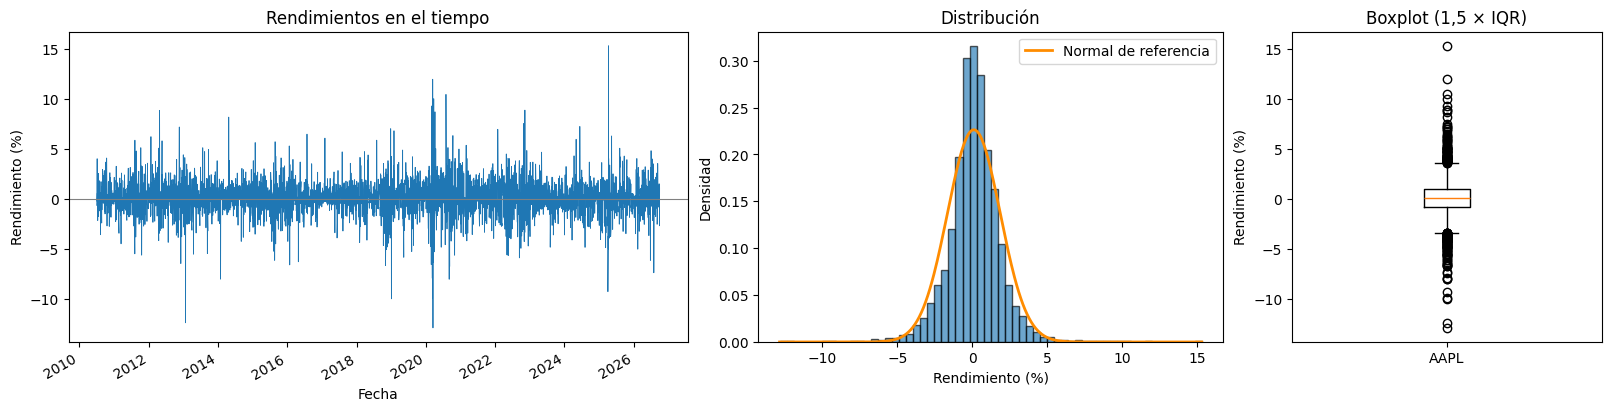

In [5]:
import numpy as np

fig, (ax_serie, ax_hist, ax_box) = plt.subplots(
    1, 3, figsize=(16, 4),
    gridspec_kw={"width_ratios": [2, 1.5, 1]},
    layout="constrained",
)

rendimiento_pct.plot(ax=ax_serie, linewidth=0.6)
ax_serie.axhline(0, color="gray", linewidth=0.8)
ax_serie.set(title="Rendimientos en el tiempo", xlabel="Fecha", ylabel="Rendimiento (%)")

ax_hist.hist(rendimiento_pct, bins=60, density=True, alpha=0.65, edgecolor="black")
x = np.linspace(rendimiento_pct.min(), rendimiento_pct.max(), 400)
ax_hist.plot(
    x,
    norm.pdf(x, loc=rendimiento_pct.mean(), scale=rendimiento_pct.std()),
    color="darkorange",
    linewidth=2,
    label="Normal de referencia",
)
ax_hist.set(title="Distribución", xlabel="Rendimiento (%)", ylabel="Densidad")
ax_hist.legend()

ax_box.boxplot(rendimiento_pct)
ax_box.set(title="Boxplot (1,5 × IQR)", ylabel="Rendimiento (%)")
ax_box.set_xticks([1], ["AAPL"])

plt.show()

Se muestra una distribución bastante simétrica aunque, un poco más angosto y alto de una distribución normal lo que mostraba la prueba de asimetría. Curtosis también indicaba las colas largas que se pueden ver en el boxplot. 

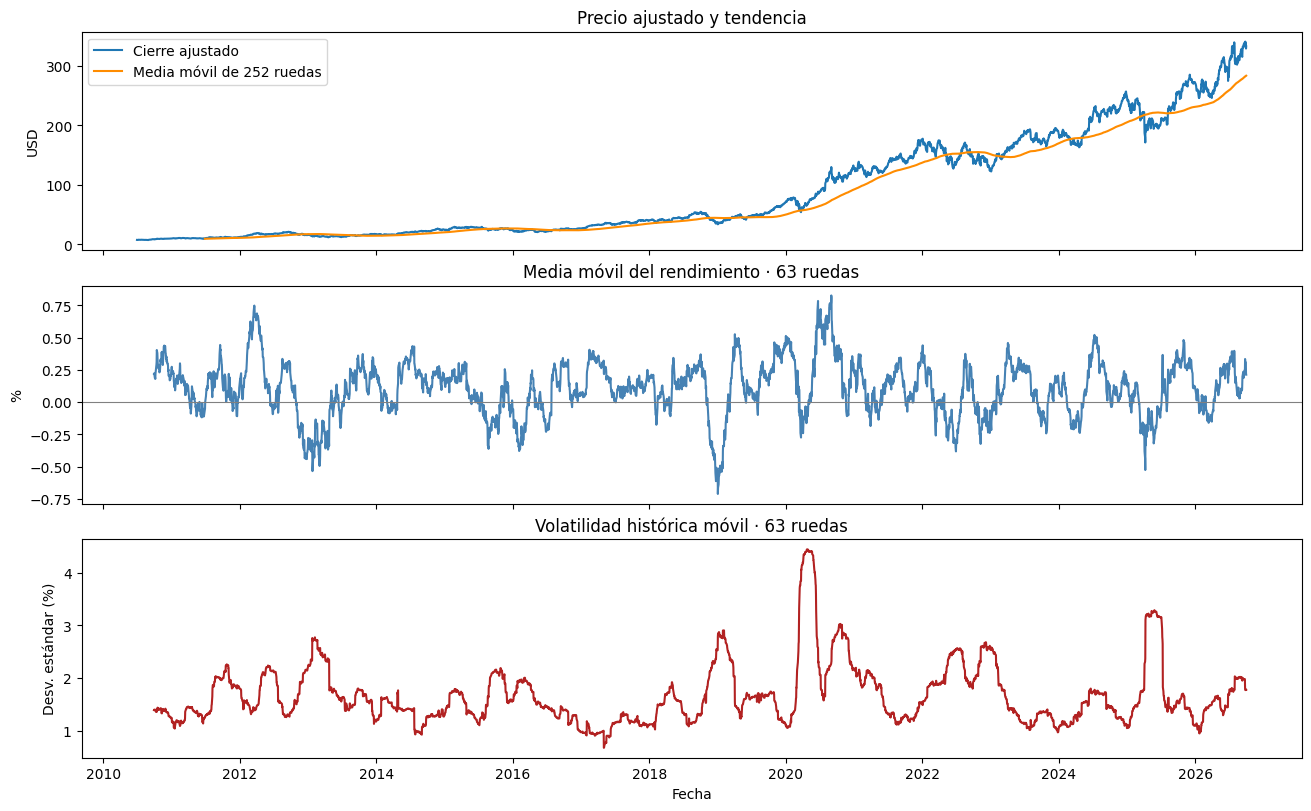

In [6]:
media_precio_252 = precio_ajustado.rolling(252).mean()

retornos_63 = rendimiento_pct.rolling(63)
media_retorno_63 = retornos_63.mean()
volatilidad_63 = retornos_63.std()

fig, (ax_precio, ax_media, ax_vol) = plt.subplots(
    3, 1, figsize=(13, 8), sharex=True, layout="constrained"
)

ax_precio.plot(precio_ajustado.index, precio_ajustado, label="Cierre ajustado")
ax_precio.plot(
    media_precio_252.index, media_precio_252,
    label="Media móvil de 252 ruedas", color="darkorange",
)
ax_precio.set(title="Precio ajustado y tendencia", ylabel="USD")
ax_precio.legend()

ax_media.plot(media_retorno_63.index, media_retorno_63, color="steelblue")
ax_media.axhline(0, color="gray", linewidth=0.8)
ax_media.set(title="Media móvil del rendimiento · 63 ruedas", ylabel="%")

ax_vol.plot(volatilidad_63.index, volatilidad_63, color="firebrick")
ax_vol.set(
    title="Volatilidad histórica móvil · 63 ruedas",
    ylabel="Desv. estándar (%)",
    xlabel="Fecha",
)

plt.show()

Se ve episodios de alta volatilidad después de 2020 y entre el 2025 y 2026

,Observaciones,Mediana,P90
Día,,,
Lunes,765,1.063,2.802
Martes,841,0.868,2.650
Miércoles,838,0.805,2.691
Jueves,822,0.798,2.615
Viernes,820,0.820,2.708


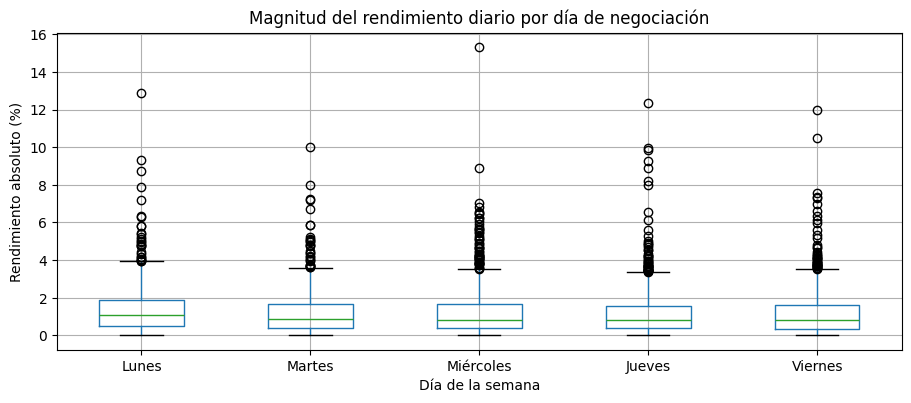

In [7]:
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]

calendario = rendimiento_pct.abs().to_frame("Magnitud (%)")
calendario["Día"] = pd.Categorical.from_codes(
    calendario.index.dayofweek,
    categories=dias,
    ordered=True,
)

por_dia = calendario.groupby("Día", observed=True)["Magnitud (%)"]

resumen_dias = por_dia.agg(
    Observaciones="size",
    Mediana="median",
    P90=lambda serie: serie.quantile(0.90),
)

display(resumen_dias.round(3))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
calendario.boxplot(column="Magnitud (%)", by="Día", ax=ax)
fig.suptitle("")
ax.set(
    title="Magnitud del rendimiento diario por día de negociación",
    xlabel="Día de la semana",
    ylabel="Rendimiento absoluto (%)",
)
plt.show()

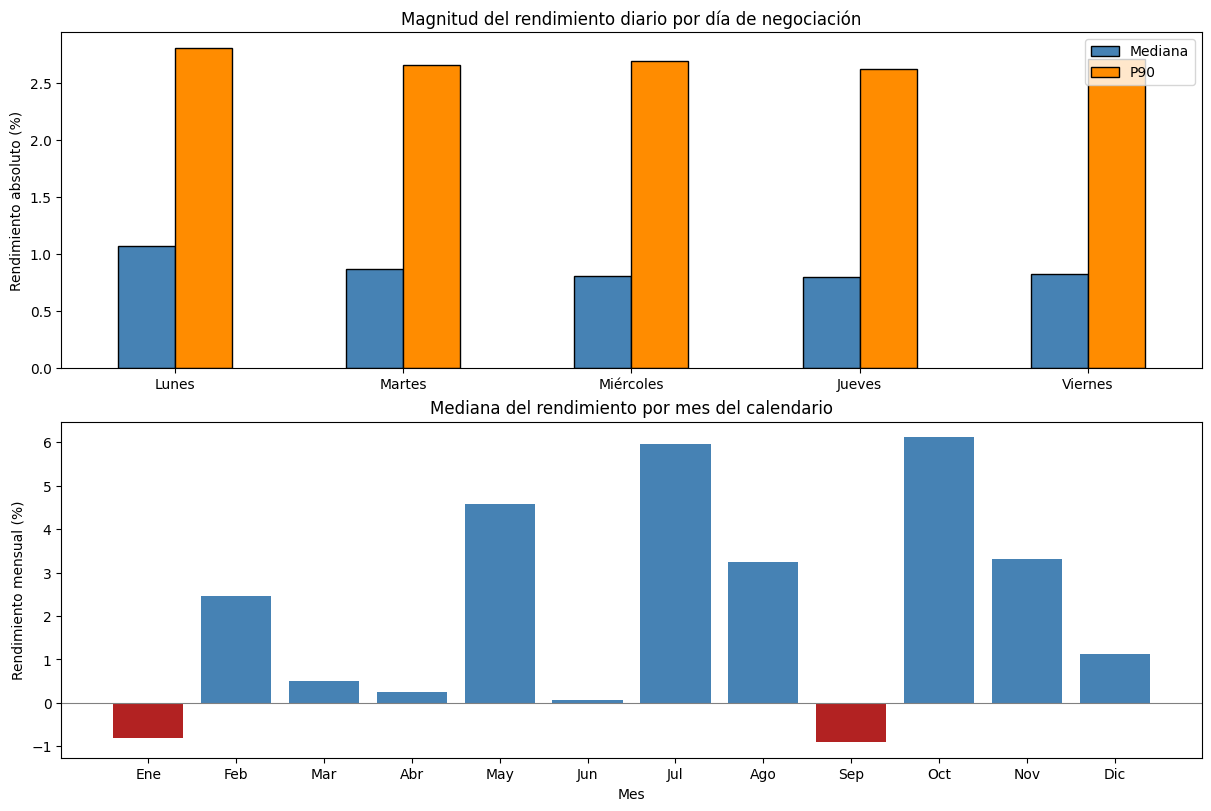

In [8]:
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# Acumular los rendimientos diarios de cada mes mediante capitalización.
factores_diarios = 1 + rendimiento_pct / 100
rendimiento_mensual_pct = (
    factores_diarios.groupby(factores_diarios.index.to_period("M"))
    .prod()
    .sub(1)
    .mul(100)
)

# El primer mes carece del rendimiento de la primera rueda de la serie.
rendimiento_mensual_pct = rendimiento_mensual_pct.iloc[1:]

mediana_mensual = (
    rendimiento_mensual_pct.groupby(rendimiento_mensual_pct.index.month)
    .median()
    .reindex(range(1, 13))
)
mediana_mensual.index = meses

fig, (ax_dias, ax_meses) = plt.subplots(
    2, 1, figsize=(12, 8), layout="constrained"
)

resumen_dias[["Mediana", "P90"]].plot.bar(
    ax=ax_dias, rot=0, color=["steelblue", "darkorange"], edgecolor = "black"
)
ax_dias.set(
    title="Magnitud del rendimiento diario por día de negociación",
    xlabel="",
    ylabel="Rendimiento absoluto (%)",
)
ax_dias.legend()

colores = [
    "steelblue" if valor >= 0 else "firebrick"
    for valor in mediana_mensual
]
ax_meses.bar(mediana_mensual.index, mediana_mensual, color=colores)
ax_meses.axhline(0, color="gray", linewidth=0.8)
ax_meses.set(
    title="Mediana del rendimiento por mes del calendario",
    xlabel="Mes",
    ylabel="Rendimiento mensual (%)",
)

plt.show()

En términos diarios, no se ve ningún día favorecido con estos datos, mientras que por mes, sí se puede ver que en Enero y Setiembre la mediana de rendimientos es negativa.

In [9]:
# ESTACIONARIEDAD

from statsmodels.tsa.stattools import adfuller

series_adf = [
    ("Log del precio ajustado", np.log(precio_ajustado), "ct"),
    ("Rendimiento diario (%)", rendimiento_pct, "c"),
]

resultados_adf = []

for nombre, serie, especificacion in series_adf:
    estadistico, p_valor, rezagos, observaciones, criticos, _ = adfuller(
        serie.dropna(),
        regression=especificacion,
        autolag="AIC",
    )

    resultados_adf.append({
        "Serie": nombre,
        "Estadístico ADF": estadistico,
        "Valor p": p_valor,
        "Valor crítico al 5 %": criticos["5%"],
        "Rezagos": rezagos,
        "Observaciones": observaciones,
        "Rechaza raíz unitaria al 5 %": p_valor < 0.05,
    })

tabla_adf = pd.DataFrame(resultados_adf).set_index("Serie")
display(tabla_adf.style.format({"Valor p": "{:.3g}"}))

C:\Users\usuario\AppData\Local\Temp\ipykernel_8288\3261544750.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, rezagos, observaciones, criticos, _ = adfuller(
C:\Users\usuario\AppData\Local\Temp\ipykernel_8288\3261544750.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estadistico, p_valor, rezagos, observaciones, criticos, _ = adfuller(


,Estadístico ADF,Valor p,Valor crítico al 5 %,Rezagos,Observaciones,Rechaza raíz unitaria al 5 %
Serie,,,,,,
Log del precio ajustado,-2.824013,0.188,-3.411567,9,4077,False
Rendimiento diario (%),-21.499862,0,-2.862249,8,4077,True


La prueba ADF tiene como hipótesis nula que se tiene una raíz unitaria y como hipótesis alternativa que la series es estacionaria. Lo que se puede ver en estos resultados es que si se tiene el logaritmo del precio de cierre ajustado, entonces no se rechaza la hipótesis nula (no estaconario), mientras que en el comportamiento del rendimiento si hay estacionaridad. 

## Target (Volatilidad futura 5 días o volatilidad futura de 5 ruedas)

La volatilidad no es más que la desviación estándar de una ventana de rendimientos. 

,Volatilidad futura (%)
count,4082.000
mean,1.498
std,0.957
min,0.076
50%,1.275
80%,2.028
95%,3.202
99%,4.852
max,10.731


Asimetría: 2.642


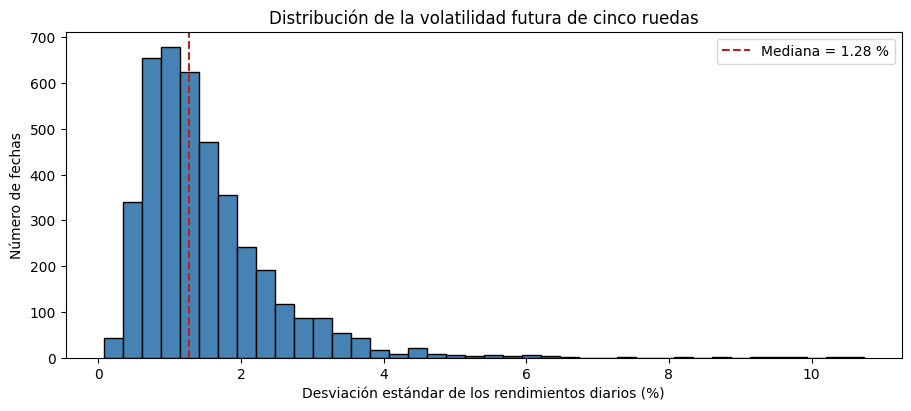

In [10]:
horizonte = 5

vol_futura_5 = (
    rendimiento_pct.reindex(precio_ajustado.index)
    .rolling(horizonte, min_periods=horizonte)
    .std(ddof=1)
    .shift(-horizonte)
    .rename("VOL_FUTURA_5")
)

vol_eda = vol_futura_5.dropna()

resumen_vol = vol_eda.describe(percentiles=[0.50, 0.80, 0.95, 0.99])
display(resumen_vol.to_frame("Volatilidad futura (%)").round(3))
print(f"Asimetría: {vol_eda.skew():.3f}")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist(vol_eda, bins=40, color="steelblue", edgecolor = "black")
ax.axvline(
    vol_eda.median(), color="firebrick", linestyle="--",
    label=f"Mediana = {vol_eda.median():.2f} %",
)
ax.set(
    title="Distribución de la volatilidad futura de cinco ruedas",
    xlabel="Desviación estándar de los rendimientos diarios (%)",
    ylabel="Número de fechas",
)
ax.legend()
plt.show()

Se puede ver una distribución asimétrica positiva con una cola sumamente larga. La desviación estándar está muy cerca del valor de la media. 

,Ventanas,Porcentaje
"IQR (1,5 × IQR)",164,4.02
Z-score (|z| ≥ 3),68,1.67
Marcados por ambos,68,1.67


Límites IQR: -0.630 % a 3.356 %
Ventanas por debajo del límite IQR: 0
Ventanas por encima del límite IQR: 164


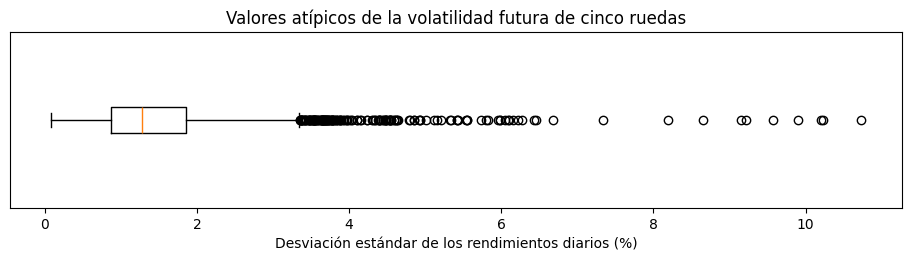

In [11]:
#DSITRIBUCIÓN TARGET Y ANÁLISIS DE OUTLIERS 

q1, q3 = vol_eda.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipico_iqr = (vol_eda < limite_inferior) | (vol_eda > limite_superior)

z_vol = (vol_eda - vol_eda.mean()) / vol_eda.std()
atipico_z = z_vol.abs() >= 3

conteos_vol = pd.Series({
    "IQR (1,5 × IQR)": atipico_iqr.sum(),
    "Z-score (|z| ≥ 3)": atipico_z.sum(),
    "Marcados por ambos": (atipico_iqr & atipico_z).sum(),
}, name="Ventanas")

display(conteos_vol.to_frame().assign(
    Porcentaje=(conteos_vol / len(vol_eda) * 100).round(2)
))

print(f"Límites IQR: {limite_inferior:.3f} % a {limite_superior:.3f} %")
print(f"Ventanas por debajo del límite IQR: {(vol_eda < limite_inferior).sum()}")
print(f"Ventanas por encima del límite IQR: {(vol_eda > limite_superior).sum()}")

fig, ax = plt.subplots(figsize=(9, 2.5), layout="constrained")
ax.boxplot(vol_eda, vert=False, whis=1.5)
ax.set(
    title="Valores atípicos de la volatilidad futura de cinco ruedas",
    xlabel="Desviación estándar de los rendimientos diarios (%)",
    yticks=[],
)
plt.show()

In [12]:
#RELACIONES TARGET Y SUS CARACTERÍSTICAS

columnas_mercado = [
    "OPEN_PRICE",
    "HIGH_PRICE",
    "LOW_PRICE",
    "CLOSE_PRICE",
    "ADJ_CLOSE_PRICE",
    "VOLUME",
]

relacion_obt = (
    df.set_index("TRADE_DATE")[columnas_mercado]
    .join(vol_eda)
    .dropna(subset=["VOL_FUTURA_5"])
)

spearman_obt = (
    relacion_obt[columnas_mercado + ["VOL_FUTURA_5"]]
    .corr(method="spearman")
    .loc[columnas_mercado, "VOL_FUTURA_5"]
    .sort_values(key=lambda rho: rho.abs(), ascending=False)
    .rename("Spearman con volatilidad futura")
)

display(spearman_obt.to_frame().round(3))

,Spearman con volatilidad futura
VOLUME,0.116
HIGH_PRICE,0.053
OPEN_PRICE,0.052
CLOSE_PRICE,0.051
LOW_PRICE,0.050
ADJ_CLOSE_PRICE,0.049


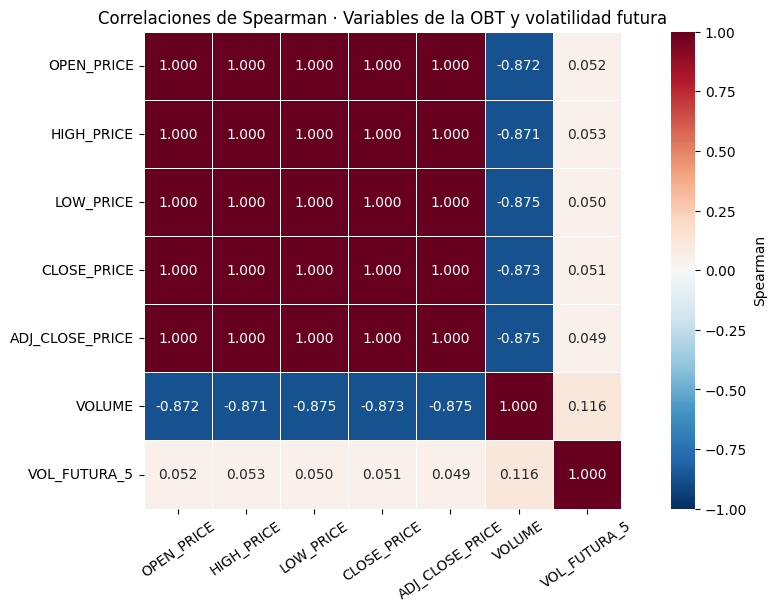

In [13]:
import seaborn as sns

correlacion_obt = (
    relacion_obt[columnas_mercado + ["VOL_FUTURA_5"]]
    .corr(method="spearman")
)

fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
sns.heatmap(
    correlacion_obt,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman"},
    ax=ax,
)
ax.set_title("Correlaciones de Spearman · Variables de la OBT y volatilidad futura")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
plt.show()

Volumen tiene la mayor correlación, aunque es un valor muy cercano a cero, es bastante débil.

Realmente, el target es clasificar la volatilidad futura de 5 ruedas como alta o baja, pero para ver distribuciones e información, era más pertinente usarla primero como variable numérica. PAra clasificar como alta o baja, se obtiene el percentil 80 de la volatilidad de 5 ruedas anual.

In [14]:
# BALANCEO DE CLASES

p80_eda = vol_eda.quantile(0.80)
clase_eda = vol_eda.gt(p80_eda).astype(int)

conteos = clase_eda.value_counts().reindex([0, 1], fill_value=0)
conteos.index = ["0 · Volatilidad baja", "1 · Volatilidad alta"]

balance_eda = conteos.to_frame("Fechas")
balance_eda["Porcentaje"] = conteos.div(len(clase_eda)).mul(100).round(2)

print(f"P80 descriptivo de la OBT: {p80_eda:.3f} %")
display(balance_eda)

por_anio = clase_eda.groupby(clase_eda.index.year).agg(["size", "sum", "mean"])
por_anio.columns = ["Fechas", "Alta volatilidad", "Proporción alta"]
por_anio["Porcentaje alta"] = por_anio.pop("Proporción alta").mul(100)
display(por_anio.round(2))

P80 descriptivo de la OBT: 2.028 %


,Fechas,Porcentaje
0 · Volatilidad baja,3265,79.99
1 · Volatilidad alta,817,20.01


,Fechas,Alta volatilidad,Porcentaje alta
TRADE_DATE,,,
2010,128,7,5.47
2011,252,45,17.86
2012,250,59,23.60
2013,252,47,18.65
2014,252,20,7.94
2015,252,51,20.24
2016,252,36,14.29
2017,251,11,4.38
2018,251,73,29.08


¡Importante! Esto solo sirve como una referencia ya que para calcular el umbral, se requiere el percentil 80 de la volatilidad de solo los datos de entrenamiento para no hacer data leakage. Por el momento se ve un 80/20 de desbalanceo, que era de esperarse por el percentil.